# 11 · Trading evaluation: is any of it worth money against the forward curve?

Notebooks 02–10 measured forecasts by RMSE. A rates position already pays or
earns the forward rate, so its P&L depends on the realised rate **relative
to the forward**. This notebook turns every forecast into trades and asks
whether any of them beats the trade that needs no model at all: carry and
roll-down (README §7.5, §8 step 8).

**The P&L identity.** Receive the forward F_t(h, τ) on a τ-month zero
starting in h months (an FRA, a rate future or a forward-starting swap
leg). Per unit of DV01 it earns 100 (F_t(h, τ) − y_{t+h}(τ)) bp at t + h.
This is exact for zero-coupon bonds: the h-month excess return of an
(h + τ)-month zero is τ/12 (F − y_{t+h}(τ)). So the curves alone give the
P&L, and no licensed contract data is needed.

**Signal.** A forecast ŷ implies s = 100 (F − ŷ): receive when s > 0. The
random walk (ŷ = y_t) gives s = F − y_t, carry plus roll-down, which earns
the term premium.

**Grid** (`yck.eval.trading.run_trading`, fixed and committed before any
P&L was looked at, commit `42de439`):

- **Signals:**
  - carry (random walk);
  - yields only;
  - the best pure model of step 7b (USD/GBP: short-hump Svensson + AR(1);
    EUR: shadow-rate + AR(1));
  - policy rate + AR(1);
  - full macro (DRA);
  - combination A.

  Outright trades also get always-receive (buy-and-hold duration).
- **Strategies:**
  - outright short end (3m; GBP 6m), 2y, 5y, 10y;
  - a DV01-neutral 2s10s steepener and 2s5s10s butterfly;
  - cross-currency 10y spreads.
- **Holding periods.** h = 6 and 12 months (all currencies), and 1 month
  (USD, EUR; GBP has no 1-month forwards). A new tranche opens every month
  and is held h months, each with 1/h of the DV01 budget.
- **Sizing,** decided at the origin:
  - `sign`: one unit of DV01;
  - `scaled`: s / σ clipped to ±2, with σ the sd of the instrument's P&L
    realised by then.
- **Costs.** 0.5 bp per unit of DV01 per leg per round trip; sensitivity
  in §5.
- **Statistics.** Sharpe ratios are of h-month returns annualised by
  √(12/h). An earlier draft annualised by √12, overstating them √h-fold. It
  was caught and fixed before this notebook was written (commit after
  `42de439`). t-statistics use autocovariances up to lag h − 1.

**Limitations.** These are curve-implied returns, not contract returns:
there is no futures basis, roll, margin or financing spread. The GSW, ECB
and BoE curves are smoothed fits. A positive result would mean "worth
testing on contract data", not "ready to trade".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
pd.set_option("display.max_rows", 300)

from yck.eval.grid import ensure_results, STANDARD_GRID, accuracy_grid, shadow_grid, svensson_grid
from yck.eval.trading import (run_trading, difference_test, ALWAYS_RECEIVE, COST_GRID_BP, BASE_COST_BP)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS, CONFIG, DATA = ROOT / "data/results", ROOT / "config/data_sources.yaml", ROOT / "data"
CCYS = ["USD", "EUR", "GBP"]
for g in (STANDARD_GRID, accuracy_grid, shadow_grid, svensson_grid):
    ensure_results(CCYS, DATA, CONFIG, grid=g)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
CAP = [{"selector": "caption", "props": "font-weight: bold; text-align: left"}]
SHORT = {"carry (random walk)": "carry", "yields": "yields", "best pure model": "best model",
         "policy rate + AR(1)": "policy rate", "full macro": "full macro",
         "combination A (inverse MSE)": "combination A", ALWAYS_RECEIVE: "always receive"}
ORDER = ["always receive", "carry", "yields", "best model", "policy rate", "full macro", "combination A"]

tab, series = run_trading(CCYS, DATA, CONFIG)
tab["sig"] = tab["signal"].map(SHORT)
tab.to_csv(RESULTS / "trading_summary.csv", index=False)
pd.DataFrame({"strategy × signal × sizing rows": [len(tab)],
              "months per test, min–max": [f"{tab.months.min():.0f}–{tab.months.max():.0f}"]})

,strategy × signal × sizing rows,"months per test, min–max"
0,692,68–297


## 1. What carry and the models earned

Cumulative net P&L (bp per unit of DV01 run) of the 10-year outright trade
at h = 12, scaled sizing, for carry, buy-and-hold, the best model and
combination A.

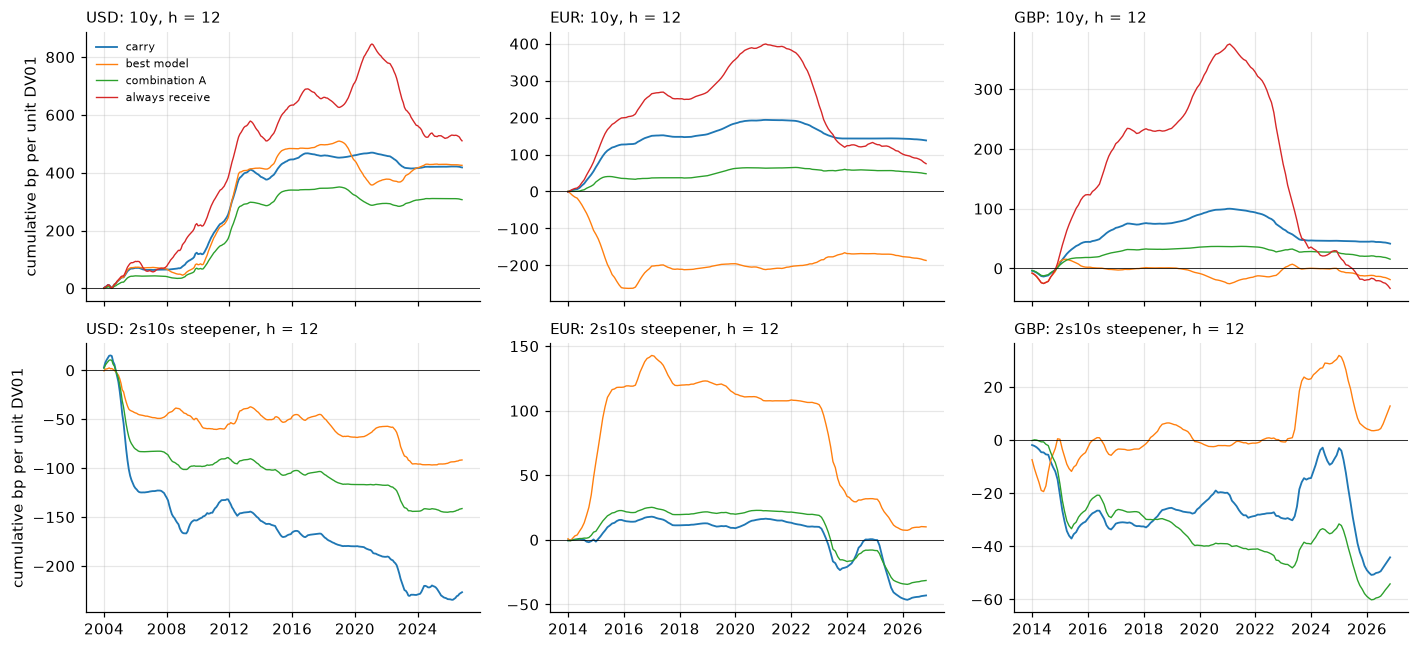

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex="col")
for j, c in enumerate(CCYS):
    for i, strat in enumerate(["10y", "2s10s steepener"]):
        ax, runs = axes[i, j], series[(c, 12, strat)]
        for name in ["carry (random walk)", "best pure model", "combination A (inverse MSE)", ALWAYS_RECEIVE]:
            key = (name, "sign") if name == ALWAYS_RECEIVE else (name, "scaled")
            if key in runs:
                ax.plot(runs[key].cumsum(), lw=1.2 if "carry" in name else 0.9, label=SHORT[name])
        ax.axhline(0, color="k", lw=0.5)
        ax.set_title(f"{c}: {strat}, h = 12", loc="left", fontsize=10)
axes[0, 0].set_ylabel("cumulative bp per unit DV01"); axes[1, 0].set_ylabel("cumulative bp per unit DV01")
axes[0, 0].legend(fontsize=7, frameon=False); fig.tight_layout()

## 2. Sharpe ratios, every strategy and signal

Net of 0.5 bp costs, scaled sizing. Buy-and-hold is shown for outright
trades only. The `sign` sizing tables follow below.

In [3]:
for sz in ("scaled", "sign"):
    t = tab[(tab.sizing == sz) | (tab.signal == ALWAYS_RECEIVE)]
    out = pd.concat({f"h = {h}": t[t.h == h].pivot_table(index=["ccy", "strategy"], columns="sig", values="sharpe")
                     .reindex(columns=ORDER) for h in (1, 6, 12)}, axis=1)
    display(out.round(2).style.set_caption(f"Sharpe ratio, {sz} sizing").set_table_styles(CAP)
            .background_gradient(cmap="RdYlGn", vmin=-1, vmax=1, axis=None).format("{:.2f}", na_rep=""))

## 3. Does any model beat carry?

Each model signal's mean net P&L minus carry's (bp per unit DV01 a year),
with its HAC t-statistic, scaled sizing. With this many comparisons some
|t| > 2 are expected by chance. The count below compares them with the
roughly 2.5% per tail that pure chance would give.

In [4]:
m = tab[(tab.sizing == "scaled") & tab.t_vs_carry.notna()]
cell = m.assign(cell=m.apply(lambda r: f"{r.vs_carry:+.1f} ({r.t_vs_carry:+.1f})", axis=1))
display(cell.pivot_table(index=["ccy", "h", "strategy"], columns="sig", values="cell", aggfunc="first")
        .reindex(columns=ORDER[2:]).style.set_caption("Model − carry: annual bp (t)").set_table_styles(CAP))
for sz in ("scaled", "sign"):
    mm = tab[(tab.sizing == sz) & tab.t_vs_carry.notna()]
    print(f"{sz}: {len(mm)} comparisons; t > 2: {int((mm.t_vs_carry > 2).sum())}, t < -2: "
          f"{int((mm.t_vs_carry < -2).sum())} (about {0.025 * len(mm):.0f} each expected by chance)")

scaled: 275 comparisons; t > 2: 10, t < -2: 13 (about 7 each expected by chance)
sign: 275 comparisons; t > 2: 9, t < -2: 5 (about 7 each expected by chance)


## 4. The macro question: do macro signals add P&L?

The README asks whether macro information pays in P&L as well as in RMSE.
The table gives the policy-rate model and the full macro model, each minus
yields only: annual bp (t), scaled sizing.

In [5]:
rows = {}
for (c, h, strat), runs in series.items():
    if ("yields", "scaled") not in runs:
        continue
    for name in ("policy rate + AR(1)", "full macro"):
        d = difference_test(runs[(name, "scaled")], runs[("yields", "scaled")], h)
        rows[(c, h, strat, SHORT[name])] = f"{d['diff']:+.1f} ({d['t']:+.1f})"
pd.Series(rows).unstack().rename_axis(["ccy", "h", "strategy"])

full macro   policy rate
ccy     h  strategy                                   
EUR     1  10y               +5.5 (+0.9)  -24.9 (-1.9)
           2s10s steepener   +0.8 (+0.1)  -29.4 (-1.8)
           2s5s10s fly       +0.8 (+0.8)  +61.4 (+5.6)
           2y                +0.5 (+0.1)   -3.1 (-0.5)
           5y                +2.2 (+0.5)   +9.0 (+1.3)
           short            -11.6 (-2.1)  -22.6 (-1.3)
        6  10y               +2.2 (+0.2)   -7.0 (-1.5)
           2s10s steepener   -4.0 (-0.3)  -11.7 (-0.9)
           2s5s10s fly       -3.1 (-1.7)  +14.5 (+2.3)
           2y                -5.4 (-0.7)   -2.5 (-0.4)
           5y                -1.3 (-0.2)   +2.9 (+1.1)
           short             +3.2 (+0.2)  -12.1 (-0.9)
        12 10y               -4.6 (-0.5)   -5.9 (-1.3)
           2s10s steepener   +2.2 (+0.2)   +0.8 (+0.1)
           2s5s10s fly       -3.1 (-1.7)   +8.9 (+2.3)
           2y               -10.2 (-1.4)   +1.2 (+0.4)
           5y                -6.8 (-1.0)   +1.9 (+0.7)
           short             -6.7 (-1.2)   -2.7 (-0.4)
EUR-GBP 6  10y spread        +3.9 (+0.6)   +0.1 (+0.0)
        12 10y spread        -1.3 (-0.3)   -2.0 (-0.8)
GBP     6  10y               +2.7 (+0.4)   +4.3 (+1.3)
           2s10s steepener   -9.1 (-0.9)   +2.8 (+0.6)
           2s5s10s fly       -0.0 (-0.0)   +2.3 (+0.7)
           2y               -26.5 (-1.3)   +6.4 (+1.2)
           5y                -8.0 (-0.8)   -1.7 (-1.0)
           short            -20.9 (-0.9)  +16.1 (+1.3)
        12 10y               -4.6 (-1.6)   +2.0 (+1.2)
           2s10s steepener   -5.5 (-0.4)   +4.3 (+1.7)
           2s5s10s fly       -0.3 (-0.1)   +0.5 (+0.1)
           2y               -47.2 (-1.9)   +2.1 (+0.5)
           5y               -20.4 (-2.0)   -1.1 (-0.6)
           short            -47.8 (-2.1)  +15.3 (+0.8)
USD     1  10y               +1.3 (+0.2)   -5.1 (-0.5)
           2s10s steepener   +9.9 (+2.0)  +15.1 (+1.4)
           2s5s10s fly       +0.3 (+0.4)  +50.5 (+4.0)
           2y                +3.0 (+0.6)   +1.5 (+0.6)
           5y                -0.0 (-0.0)   +7.1 (+1.5)
           short             +5.1 (+0.8)   -0.3 (-0.0)
        6  10y               -1.7 (-0.2)   -0.5 (-0.2)
           2s10s steepener  +10.7 (+1.6)   +5.3 (+1.7)
           2s5s10s fly       +1.4 (+0.8)  +11.4 (+2.0)
           2y                +3.5 (+0.4)   +2.0 (+1.2)
           5y                -1.4 (-0.2)   +4.0 (+1.9)
           short            +11.3 (+1.2)   +5.5 (+1.1)
        12 10y               -2.9 (-0.3)   +2.7 (+1.2)
           2s10s steepener   +4.8 (+0.8)   +4.9 (+2.2)
           2s5s10s fly       +0.3 (+0.1)   +6.7 (+1.3)
           2y                -2.0 (-0.2)   +1.6 (+1.3)
           5y                -1.6 (-0.1)   +4.0 (+1.7)
           short             +1.8 (+0.3)   +3.1 (+1.1)
USD-EUR 1  10y spread        -2.7 (-0.3)   +0.5 (+0.1)
        6  10y spread        -5.3 (-0.6)   -2.9 (-0.7)
        12 10y spread        -5.9 (-0.9)   -3.5 (-1.8)
USD-GBP 6  10y spread        +0.6 (+0.1)   -1.2 (-0.5)
        12 10y spread        +3.3 (+0.3)   -1.5 (-0.6)

## 5. Cost sensitivity

The Sharpe ratio of each signal's best strategy at h = 12 (by net Sharpe at
the base cost), and of carry on the same strategy, at costs from 0 to 2 bp
per unit of DV01 per leg.

In [6]:
by_cost = {c: run_trading(CCYS, DATA, CONFIG, cost_bp=c)[0] for c in COST_GRID_BP}
base = tab[(tab.h == 12) & (tab.sizing == "scaled") & (tab.signal != ALWAYS_RECEIVE)]
rows = {}
for (ccy, name), g in base.groupby(["ccy", "signal"]):
    strat = g.loc[g.sharpe.idxmax(), "strategy"]
    for nm in (name, "carry (random walk)"):
        key = (ccy, SHORT[name], strat, SHORT[nm])
        rows[key] = {f"{c:g} bp": by_cost[c].query("ccy == @ccy and h == 12 and sizing == 'scaled' and "
                                                   "strategy == @strat and signal == @nm").sharpe.iloc[0]
                     for c in COST_GRID_BP}
pd.DataFrame(rows).T.round(2).rename_axis(["ccy", "signal's best", "strategy", "shown"])

0 bp  0.25 bp  0.5 bp  \
ccy     signal's best strategy        shown                                  
EUR     best model    2s5s10s fly     best model     0.12     0.08    0.03   
                                      carry          0.38     0.33    0.28   
        carry         10y             carry          0.33     0.33    0.33   
        combination A 2s5s10s fly     combination A  0.43     0.39    0.35   
                                      carry          0.38     0.33    0.28   
        full macro    2s10s steepener full macro     0.10     0.10    0.09   
                                      carry         -0.13    -0.14   -0.15   
        policy rate   2s5s10s fly     policy rate    0.24     0.20    0.16   
                                      carry          0.38     0.33    0.28   
        yields        2s10s steepener yields         0.12     0.12    0.11   
                                      carry         -0.13    -0.14   -0.15   
EUR-GBP best model    10y spread      best model    -0.42    -0.42   -0.43   
                                      carry         -0.03    -0.04   -0.06   
        carry         10y spread      carry         -0.03    -0.04   -0.06   
        combination A 10y spread      combination A -0.27    -0.28   -0.28   
                                      carry         -0.03    -0.04   -0.06   
        full macro    10y spread      full macro    -0.20    -0.21   -0.22   
                                      carry         -0.03    -0.04   -0.06   
        policy rate   10y spread      policy rate   -0.26    -0.26   -0.27   
                                      carry         -0.03    -0.04   -0.06   
        yields        10y spread      yields        -0.24    -0.25   -0.25   
                                      carry         -0.03    -0.04   -0.06   
GBP     best model    2y              best model     0.40     0.39    0.39   
                                      carry          0.22     0.22    0.22   
        carry         2y              carry          0.22     0.22    0.22   
        combination A 5y              combination A  0.28     0.27    0.27   
                                      carry          0.20     0.20    0.20   
        full macro    2s10s steepener full macro    -0.07    -0.08   -0.09   
                                      carry         -0.14    -0.15   -0.16   
        policy rate   2y              policy rate    0.37     0.37    0.37   
                                      carry          0.22     0.22    0.22   
        yields        2y              yields         0.38     0.37    0.37   
                                      carry          0.22     0.22    0.22   
USD     best model    10y             best model     0.32     0.32    0.32   
                                      carry          0.41     0.40    0.40   
        carry         10y             carry          0.41     0.40    0.40   
        combination A 10y             combination A  0.36     0.36    0.36   
                                      carry          0.41     0.40    0.40   
        full macro    10y             full macro     0.19     0.19    0.19   
                                      carry          0.41     0.40    0.40   
        policy rate   10y             policy rate    0.33     0.33    0.33   
                                      carry          0.41     0.40    0.40   
        yields        10y             yields         0.31     0.31    0.31   
                                      carry          0.41     0.40    0.40   
USD-EUR best model    10y spread      best model    -0.27    -0.28   -0.29   
                                      carry         -0.09    -0.10   -0.11   
        carry         10y spread      carry         -0.09    -0.10   -0.11   
        combination A 10y spread      combination A -0.20    -0.21   -0.22   
                                      carry         -0.09    -0.10   -0.11   
        full macro    10y spread      full macro    -0.29    -0.30   -0.31 

## 6. Takeaways

1. **Carry is the strategy to beat, and no model reliably beats it.**
   - **Carry's Sharpe ratios** (h = 12, scaled, after costs):

     | | Carry | Buy-and-hold |
     |---|---|---|
     | USD 10y | 0.40 | 0.26 |
     | USD 5y | 0.38 | 0.28 |
     | EUR 10y | 0.33 | 0.07 |
     | GBP 2y–10y | 0.15–0.22 | below zero |

     Receiving the forward wherever the curve is steep collects the term
     premium without forecasting anything.
   - **The models trail carry on the trades where carry is strongest:**
     USD 10y 0.19–0.36, EUR 10y −0.27 to 0.26.
   - **The counts are at chance level.** Across 275 model-versus-carry
     comparisons, t > 2 occurs 10 times with scaled sizing and 9 with sign
     sizing, against about 7 expected by chance. t < −2 occurs 13 and 5
     times.
2. **Where models look better, it is small or unreliable.**
   - **GBP 2y at h = 12:** Sharpe 0.37–0.39 for yields, the best model and
     the policy-rate model, against carry's 0.22. But the difference in
     mean P&L is not significant.
   - **The USD short end at one month** beats carry significantly
     (t = 2.8–3.4 for yields, policy rate, full macro and combination A),
     but only because carry loses there (−0.51). The models' own Sharpe
     ratios are −0.16 to 0.18.
   - **EUR 2s10s at one month:** 0.42–0.71 against carry's 0.11
     (t = 2.1–2.8 for yields, full macro and combination A).
   - **Combination A** is never far behind carry and is the best model
     signal on the USD and EUR 10y.
3. **Clear losers.**
   - **Butterflies** built from models with a poor curvature forecast: the
     yields-only and full macro flies have Sharpe ratios of −0.3 to −1.6,
     and t down to −5 against carry.
   - **Cross-currency 10y spreads** lose for every signal, carry included.
4. **The macro question: the policy rate pays in USD curve trades.**
   - **Policy-rate model against yields only, USD:** higher mean P&L in 15
     of 18 strategy-horizon pairs. It is significant for the butterfly at
     one and six months (t = 4.0, 2.0) and the 2s10s steepener at 12
     months (t = 2.2). This matches the RMSE result of notebook 03.
   - **The full macro model** adds nothing in USD and EUR, and loses
     against yields only in GBP (t ≈ −2 at the short end and 5y, h = 12).
5. **Costs barely matter at h = 12.** Each unit of DV01 turns over about
   once a year. Up to 2 bp per leg, Sharpe ratios fall by at most 0.05 on
   single-maturity trades. The multi-leg butterflies fall the most (EUR
   carry fly from 0.28 to −0.01).
6. **Bottom line.** This matches the RMSE results (no model beats the
   forward curve) and Thornton & Valente (2012): statistical predictability
   does not become economic value against forwards. The only robust edge
   is the term premium, which carry earns without a model. Two signals
   would be worth testing on contract data:
   - **the policy-rate model on USD curve trades;**
   - **the GBP 2y result,** with the caveat that its mean P&L difference is
     not significant.